# Cong Hoa signal-control dataset analysis

This notebook analyses the selected **132-run checkpoint**. It rebuilds coverage, journey summaries and paired comparisons from `dataset.csv`, then checks them against the saved experiment tables. All tables and figures are calculated by the cells below.

Open this notebook in VS Code, select the project's `.venv` Python kernel and choose **Run All**. Required packages are listed in `requirements-analysis.txt`.

The experiment contains 11 methods, three demand scales and four seeds. Each run contains four tracked journeys. The primary comparison policy requires all four journeys to finish. Network events remain visible under this policy. The source audit has `accepted = false`.

In [1]:
from pathlib import Path
from itertools import product
from importlib import metadata
import hashlib
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "traffic_study").is_dir())
sys.path.insert(0, str(ROOT))
from traffic_study.dataset import valid_pair, pairwise_rows

SOURCE = ROOT / "tan_binh_2026/dataset_cong_hoa/checkpoints/132_runs"
OUTPUT = ROOT / "analysis/outputs/cong_hoa_132_runs"
OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT / "figures").mkdir(exist_ok=True)

METHOD_LABELS = {
    "fixed_time": "Fixed-time", "switching_loss_mp": "Switching-Loss MP",
    "c_mp": "C-MP", "td_mp_2023": "TD-MP", "cv_mp_2025": "CV-MP",
    "queue_responsive_2026": "Queue-responsive", "cn_mp_2024": "CN-MP",
    "wncn_mp_2024": "WNCN-MP", "wstar_ncn_mp_2024": "W*NCN-MP",
    "wstar_cn_mp_2024": "W*CN-MP", "coordinated_auction_2024": "Coordinated Auction",
}
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
pd.set_option("display.max_columns", 20)

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

plan = read_json(SOURCE / "plan.json")
snapshot = read_json(SOURCE / "snapshot.json")
audit = read_json(SOURCE / "acceptance.json")
data = pd.read_csv(SOURCE / "dataset.csv")
source_hashes = {name: sha256(SOURCE / name) for name in
                 ["dataset.csv", "summary.csv", "pairwise.csv", "plan.json", "acceptance.json"]}
print("Python", sys.version.split()[0])
print("Source", SOURCE)
print("Source audit accepted", snapshot["accepted"])
display(data.head())

Python 3.13.15
Source D:\UoG\Year 3\Final Year Project\NetWorks\grid20\tan_binh_2026\dataset_cong_hoa\checkpoints\132_runs
Source audit accepted False


,run_id,scenario,method,probe_id,vehicle_type,route_variant,completed,censored,departed,travel_time_s,...,input_sha256,map_generation_ratio,arrived_network_vehicles,running_network_vehicles,pending_network_vehicles,inserted_network_vehicles,mean_network_speed_mps,halted_network_vehicles,paired_valid,improvement_vs_fixed_percent
0,d0.1_s100/c_mp,d0.1_s100,c_mp,probe_car,car,outer,True,False,True,228.00,...,f0e8dc39abb13737add66508fda8e0b972b56922a825c9...,1.000148,142,846,9,988,9.69,260,True,27.676447
1,d0.1_s100/c_mp,d0.1_s100,c_mp,probe_motorcycle,motorcycle,outer,True,False,True,229.50,...,f0e8dc39abb13737add66508fda8e0b972b56922a825c9...,1.000148,142,846,9,988,9.69,260,True,26.910828
2,d0.1_s100/c_mp,d0.1_s100,c_mp,probe_car_center,car,center,True,False,True,228.00,...,f0e8dc39abb13737add66508fda8e0b972b56922a825c9...,1.000148,142,846,9,988,9.69,260,True,27.676447
3,d0.1_s100/c_mp,d0.1_s100,c_mp,probe_motorcycle_center,motorcycle,center,True,False,True,225.25,...,f0e8dc39abb13737add66508fda8e0b972b56922a825c9...,1.000148,142,846,9,988,9.69,260,True,27.862290
4,d0.1_s100/cn_mp_2024,d0.1_s100,cn_mp_2024,probe_car,car,outer,True,False,True,217.75,...,f0e8dc39abb13737add66508fda8e0b972b56922a825c9...,1.000148,123,845,9,968,9.05,307,True,30.927835


## 1. Experimental units and integrity checks

One row represents one tracked vehicle in one run. A run is identified by method, demand scale and seed. The four tracked vehicles share a traffic realisation, so they are analysed in separate vehicle-type and path groups. Each group has at most four seed observations.

The checks below verify the planned experiment grid, completion flags, missing travel times and run-level consistency. A censored journey has no measured arrival time. Its travel time remains missing.

In [2]:
BOOLEAN_COLUMNS = ["completed", "censored", "departed", "valid_for_comparison",
    "is_reference", "all_four_arrived", "clean_run", "probe_teleported",
    "probe_collision", "paired_valid"]
for column in BOOLEAN_COLUMNS:
    assert data[column].isin([True, False]).all(), column

assert not data.duplicated(["run_id", "probe_id"]).any()
assert data.groupby("run_id").size().eq(4).all()
assert data.groupby("run_id")["probe_id"].nunique().eq(4).all()
assert data["completed"].eq(~data["censored"]).all()
assert data.loc[data["completed"], "travel_time_s"].gt(0).all()
assert data.loc[data["censored"], "travel_time_s"].isna().all()
assert data["all_four_arrived"].eq(data.groupby("run_id")["completed"].transform("all")).all()
assert data["valid_for_comparison"].eq(data["all_four_arrived"]).all()

RUN_COLUMNS = ["scenario", "method", "demand_scale", "seed", "all_four_arrived",
    "collisions", "teleports", "input_sha256", "network_sha256", "actual_end_s"]
assert data.groupby("run_id")[RUN_COLUMNS].nunique(dropna=False).le(1).all().all()
runs = data.drop_duplicates("run_id").copy()
runs["event_affected"] = runs["collisions"].gt(0) | runs["teleports"].gt(0)
expected = set(product(plan["methods"], plan["scales"], plan["seeds"]))
actual = set(runs[["method", "demand_scale", "seed"]].itertuples(index=False, name=None))
assert expected == actual
assert len(runs) == snapshot["completed_runs"] == 132
assert len(data) == snapshot["probe_rows"] == 528
print("Passed structural checks for", len(runs), "runs and", len(data), "probe records.")

Passed structural checks for 132 runs and 528 probe records.


## 2. Completion coverage and source quality

Event counts are summed once per run. Summing the same run-level count across four probe rows would multiply the reported total by four. Completion and event flags describe different properties of the data.

In [3]:
run_coverage = runs.groupby("demand_scale").agg(
    runs=("run_id", "size"), all_four_arrived=("all_four_arrived", "sum"),
    event_affected_runs=("event_affected", "sum"),
    collisions=("collisions", "sum"), teleports=("teleports", "sum"))
probe_coverage = data.groupby("demand_scale").agg(
    probe_records=("probe_id", "size"), arrived=("completed", "sum"), censored=("censored", "sum"))
coverage = run_coverage.join(probe_coverage)
coverage["run_completion_percent"] = 100 * coverage["all_four_arrived"] / coverage["runs"]
coverage["probe_completion_percent"] = 100 * coverage["arrived"] / coverage["probe_records"]
assert coverage["all_four_arrived"].sum() == snapshot["all_four_arrived_runs"]
assert coverage["censored"].sum() == snapshot["censored_probes"]
assert coverage["collisions"].sum() == snapshot["collisions"]
assert coverage["teleports"].sum() == snapshot["teleports"]
assert coverage["event_affected_runs"].sum() == snapshot["event_affected_runs"]
display(coverage.round(2))
probe_events = data.loc[data["probe_collision"] | data["probe_teleported"],
    ["run_id", "probe_id", "completed", "probe_collision", "probe_teleported"]]
display(probe_events)
print("Censored journeys by vehicle and path")
display(data.groupby(["demand_scale", "vehicle_type", "route_variant"])["censored"].sum().unstack())

,runs,all_four_arrived,event_affected_runs,collisions,teleports,probe_records,arrived,censored,run_completion_percent,probe_completion_percent
demand_scale,,,,,,,,,,
0.1,44,44,9,9,9,176,176,0,100.00,100.00
0.5,44,44,42,184,184,176,176,0,100.00,100.00
1.0,44,27,44,481,481,176,142,34,61.36,80.68


,run_id,probe_id,completed,probe_collision,probe_teleported
291,d0.5_s102/switching_loss_mp,probe_motorcycle_center,True,True,True


Censored journeys by vehicle and path


route_variant              center  outer
demand_scale vehicle_type               
0.1          car                0      0
             motorcycle         0      0
0.5          car                0      0
             motorcycle         0      0
1.0          car                0     17
             motorcycle         0     17

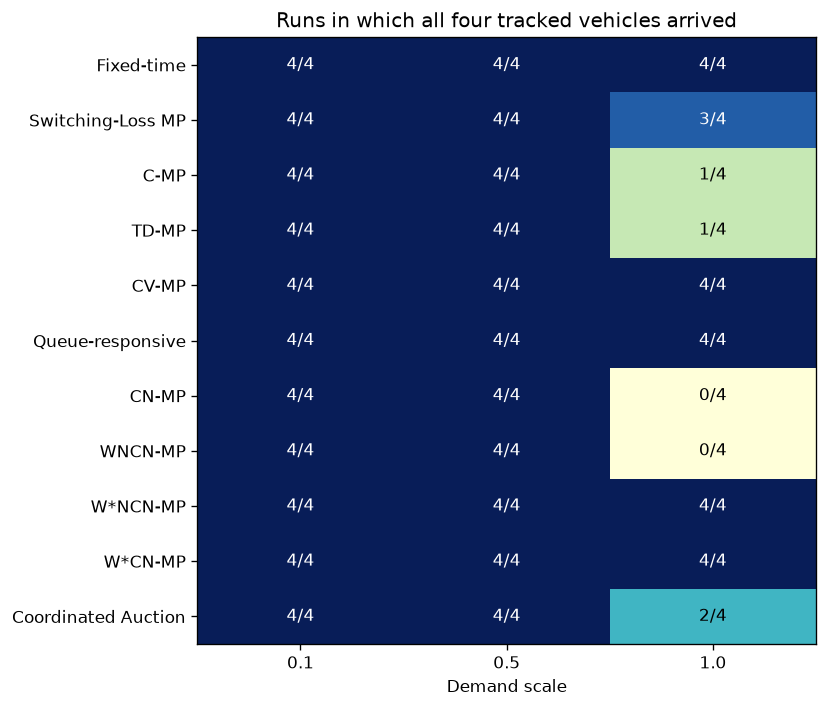

In [4]:
completion = runs.pivot_table(index="method", columns="demand_scale",
    values="all_four_arrived", aggfunc="sum").reindex(plan["methods"])
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(completion, cmap="YlGnBu", vmin=0, vmax=len(plan["seeds"]), aspect="auto")
ax.set_yticks(range(len(completion)), [METHOD_LABELS[m] for m in completion.index])
ax.set_xticks(range(len(completion.columns)), [str(s) for s in completion.columns])
for row in range(len(completion)):
    for col in range(len(completion.columns)):
        count = int(completion.iloc[row, col])
        ax.text(col, row, f"{count}/{len(plan['seeds'])}", ha="center", va="center",
                color="white" if count >= 3 else "black")
ax.set(xlabel="Demand scale", title="Runs in which all four tracked vehicles arrived")
fig.tight_layout()
fig.savefig(OUTPUT / "figures/completion.png", dpi=220)
plt.show()

## 3. Recalculate matched comparisons

A comparison matches the same demand scale, seed and tracked vehicle. It also requires matching input hashes, simulator backend and engine version. Both runs must meet the selected completion policy.

Travel-time difference (seconds) = time for method A − time for method B.

Improvement over B (%) = 100 × (time for B − time for A) / time for B.

A negative difference means A is faster. A positive percentage means A is faster. Percentages are calculated for each matched seed before taking their mean.

In [5]:
records = data.astype(object).where(pd.notna(data), None).to_dict("records")
references = {(r["demand_scale"], r["seed"], r["probe_id"]): r
              for r in records if r["method"] == "fixed_time"}
fixed_pairs = data.copy()
recalculated_flags, gains = [], []
for record in records:
    reference = references[(record["demand_scale"], record["seed"], record["probe_id"])]
    eligible = valid_pair(record, reference)
    recalculated_flags.append(eligible)
    gains.append(100 * (reference["travel_time_s"] - record["travel_time_s"])
                 / reference["travel_time_s"] if eligible else np.nan)
assert np.array_equal(recalculated_flags, data["paired_valid"])
assert np.allclose(gains, data["improvement_vs_fixed_percent"], equal_nan=True)
fixed_pairs["paired_valid"] = recalculated_flags
fixed_pairs["improvement_vs_fixed_percent"] = gains

pairs = pd.DataFrame(pairwise_rows(records))
PAIR_KEYS = ["demand_scale", "seed", "probe_id", "method_a", "method_b"]
saved_pairs = pd.read_csv(SOURCE / "pairwise.csv").set_index(PAIR_KEYS).sort_index()
rebuilt_pairs = pairs.set_index(PAIR_KEYS).sort_index()
assert saved_pairs.index.equals(rebuilt_pairs.index)
assert saved_pairs["paired_valid"].equals(rebuilt_pairs["paired_valid"])
for column in ["difference_a_minus_b_s", "improvement_a_vs_b_percent"]:
    assert np.allclose(saved_pairs[column], rebuilt_pairs[column], equal_nan=True)
assert pairs["paired_valid"].sum() == snapshot["valid_pairwise_rows"]
print("Fixed-time comparisons verified", sum(recalculated_flags))
print("Eligible method pairs", pairs["paired_valid"].sum(), "of", len(pairs))

Fixed-time comparisons verified 460
Eligible method pairs 2088 of 2640


## 4. Journey summaries and fixed-time comparison

The main journey table uses the all-four-arrived policy. It reports the number of eligible seeds alongside means and sample standard deviations. Groups with no eligible seeds retain missing means. A standard deviation needs at least two observations.

Waiting time is time spent stationary during the journey. Departure delay measures waiting to enter the simulation and is reported separately. Travel time covers actual departure to arrival.

In [6]:
GROUPS = ["demand_scale", "method", "probe_id", "vehicle_type", "route_variant"]
eligible = fixed_pairs.loc[fixed_pairs["valid_for_comparison"]]
counts = fixed_pairs.groupby(GROUPS).agg(
    planned_seeds=("seed", "size"), completed_probes=("completed", "sum"))
metrics = eligible.groupby(GROUPS).agg(
    valid_seeds=("seed", "size"), mean_travel_time_s=("travel_time_s", "mean"),
    std_travel_time_s=("travel_time_s", "std"), mean_waiting_time_s=("waiting_time_s", "mean"),
    std_waiting_time_s=("waiting_time_s", "std"), mean_time_loss_s=("time_loss_s", "mean"),
    mean_waiting_count=("waiting_count", "mean"), mean_depart_delay_s=("depart_delay_s", "mean"))
paired_metrics = fixed_pairs.loc[fixed_pairs["paired_valid"]].groupby(GROUPS).agg(
    paired_valid_seeds=("seed", "size"),
    mean_improvement_vs_fixed_percent=("improvement_vs_fixed_percent", "mean"))
journey_summary = counts.join(metrics).join(paired_metrics).reset_index()
for column in ["valid_seeds", "paired_valid_seeds"]:
    journey_summary[column] = journey_summary[column].fillna(0).astype(int)

saved_summary = pd.read_csv(SOURCE / "summary.csv").set_index(GROUPS[:3]).sort_index()
rebuilt_summary = journey_summary.set_index(GROUPS[:3]).sort_index()
for saved, rebuilt in [("valid_runs", "valid_seeds"),
    ("mean_travel_time_s", "mean_travel_time_s"), ("std_travel_time_s", "std_travel_time_s"),
    ("paired_valid_runs", "paired_valid_seeds"),
    ("mean_paired_improvement_percent", "mean_improvement_vs_fixed_percent")]:
    assert np.allclose(saved_summary[saved], rebuilt_summary[rebuilt], equal_nan=True)
baseline = journey_summary.loc[journey_summary["method"] == "fixed_time"]
display(baseline.round(2))
print("Recalculated summaries agree with summary.csv.")

,demand_scale,method,probe_id,vehicle_type,route_variant,planned_seeds,completed_probes,valid_seeds,mean_travel_time_s,std_travel_time_s,mean_waiting_time_s,std_waiting_time_s,mean_time_loss_s,mean_waiting_count,mean_depart_delay_s,paired_valid_seeds,mean_improvement_vs_fixed_percent
16,0.1,fixed_time,probe_car,car,outer,4,4,4,315.31,0.24,97.94,7.64,126.38,3.00,0.0,4,0.0
17,0.1,fixed_time,probe_car_center,car,center,4,4,4,315.06,0.43,87.94,0.43,125.51,3.00,0.5,4,0.0
18,0.1,fixed_time,probe_motorcycle,motorcycle,outer,4,4,4,313.06,0.63,108.69,2.15,123.96,3.00,0.0,4,0.0
19,0.1,fixed_time,probe_motorcycle_center,motorcycle,center,4,4,4,312.25,0.00,108.69,0.24,122.61,3.00,0.5,4,0.0
60,0.5,fixed_time,probe_car,car,outer,4,4,4,315.06,0.37,101.00,1.97,126.18,3.00,0.0,4,0.0
61,0.5,fixed_time,probe_car_center,car,center,4,4,4,315.06,0.12,86.81,1.12,125.59,3.00,0.5,4,0.0
62,0.5,fixed_time,probe_motorcycle,motorcycle,outer,4,4,4,314.31,0.62,103.19,2.88,125.20,3.00,0.0,4,0.0
63,0.5,fixed_time,probe_motorcycle_center,motorcycle,center,4,4,4,312.38,0.14,108.88,0.14,122.60,3.00,0.5,4,0.0
104,1.0,fixed_time,probe_car,car,outer,4,4,4,346.56,45.95,114.56,49.96,157.66,3.75,0.0,4,0.0
105,1.0,fixed_time,probe_car_center,car,center,4,4,4,314.94,0.24,90.00,4.17,125.48,3.00,0.5,4,0.0


Recalculated summaries agree with summary.csv.


## 5. Select the analysis view

Change these selectors and rerun the subsequent cells to inspect another demand level, vehicle type, path or pair of methods. Earlier validation covers the complete checkpoint. The exported journey tables retain all strata.

In [7]:
FOCUS_SCALE = 0.5
FOCUS_VEHICLE = "car"
FOCUS_PATH = "outer"
METHOD_A = "switching_loss_mp"
METHOD_B = "fixed_time"
assert FOCUS_SCALE in plan["scales"]
assert FOCUS_VEHICLE in ["car", "motorcycle"]
assert FOCUS_PATH in ["center", "outer"]
assert METHOD_A in plan["methods"] and METHOD_B in plan["methods"] and METHOD_A != METHOD_B
focus_summary = journey_summary.loc[
    journey_summary["demand_scale"].eq(FOCUS_SCALE)
    & journey_summary["vehicle_type"].eq(FOCUS_VEHICLE)
    & journey_summary["route_variant"].eq(FOCUS_PATH)]
display(focus_summary[["method", "valid_seeds", "mean_travel_time_s", "std_travel_time_s",
    "mean_waiting_time_s", "mean_improvement_vs_fixed_percent"]].round(2))

,method,valid_seeds,mean_travel_time_s,std_travel_time_s,mean_waiting_time_s,mean_improvement_vs_fixed_percent
44,c_mp,4,260.56,27.41,16.25,17.29
48,cn_mp_2024,4,270.69,28.80,23.94,14.08
52,coordinated_auction_2024,4,449.50,79.47,140.94,-42.67
56,cv_mp_2025,4,295.56,49.50,44.69,6.20
60,fixed_time,4,315.06,0.37,101.00,0.00
64,queue_responsive_2026,4,342.25,54.36,87.19,-8.63
68,switching_loss_mp,4,290.06,36.44,39.25,7.93
72,td_mp_2023,4,271.69,15.45,23.94,13.77
76,wncn_mp_2024,4,276.62,28.84,16.44,12.19
80,wstar_cn_mp_2024,4,276.25,31.71,30.81,12.31


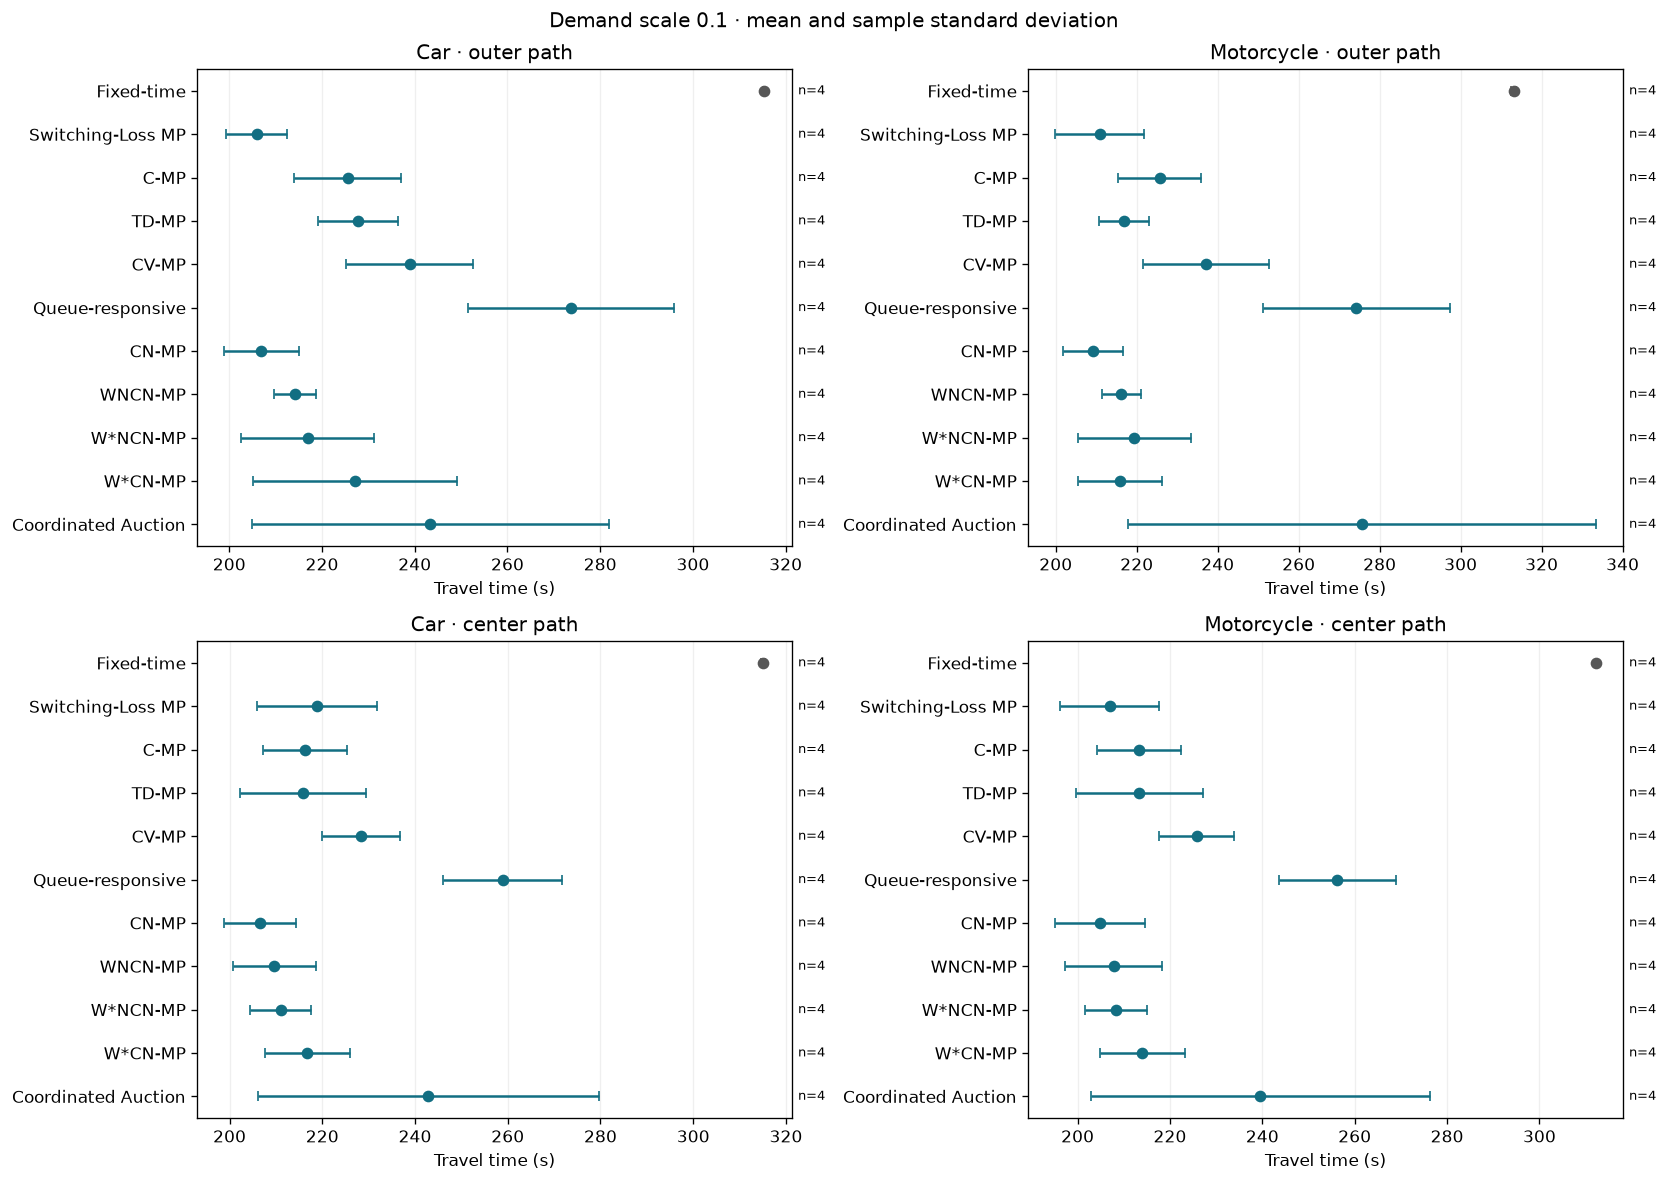

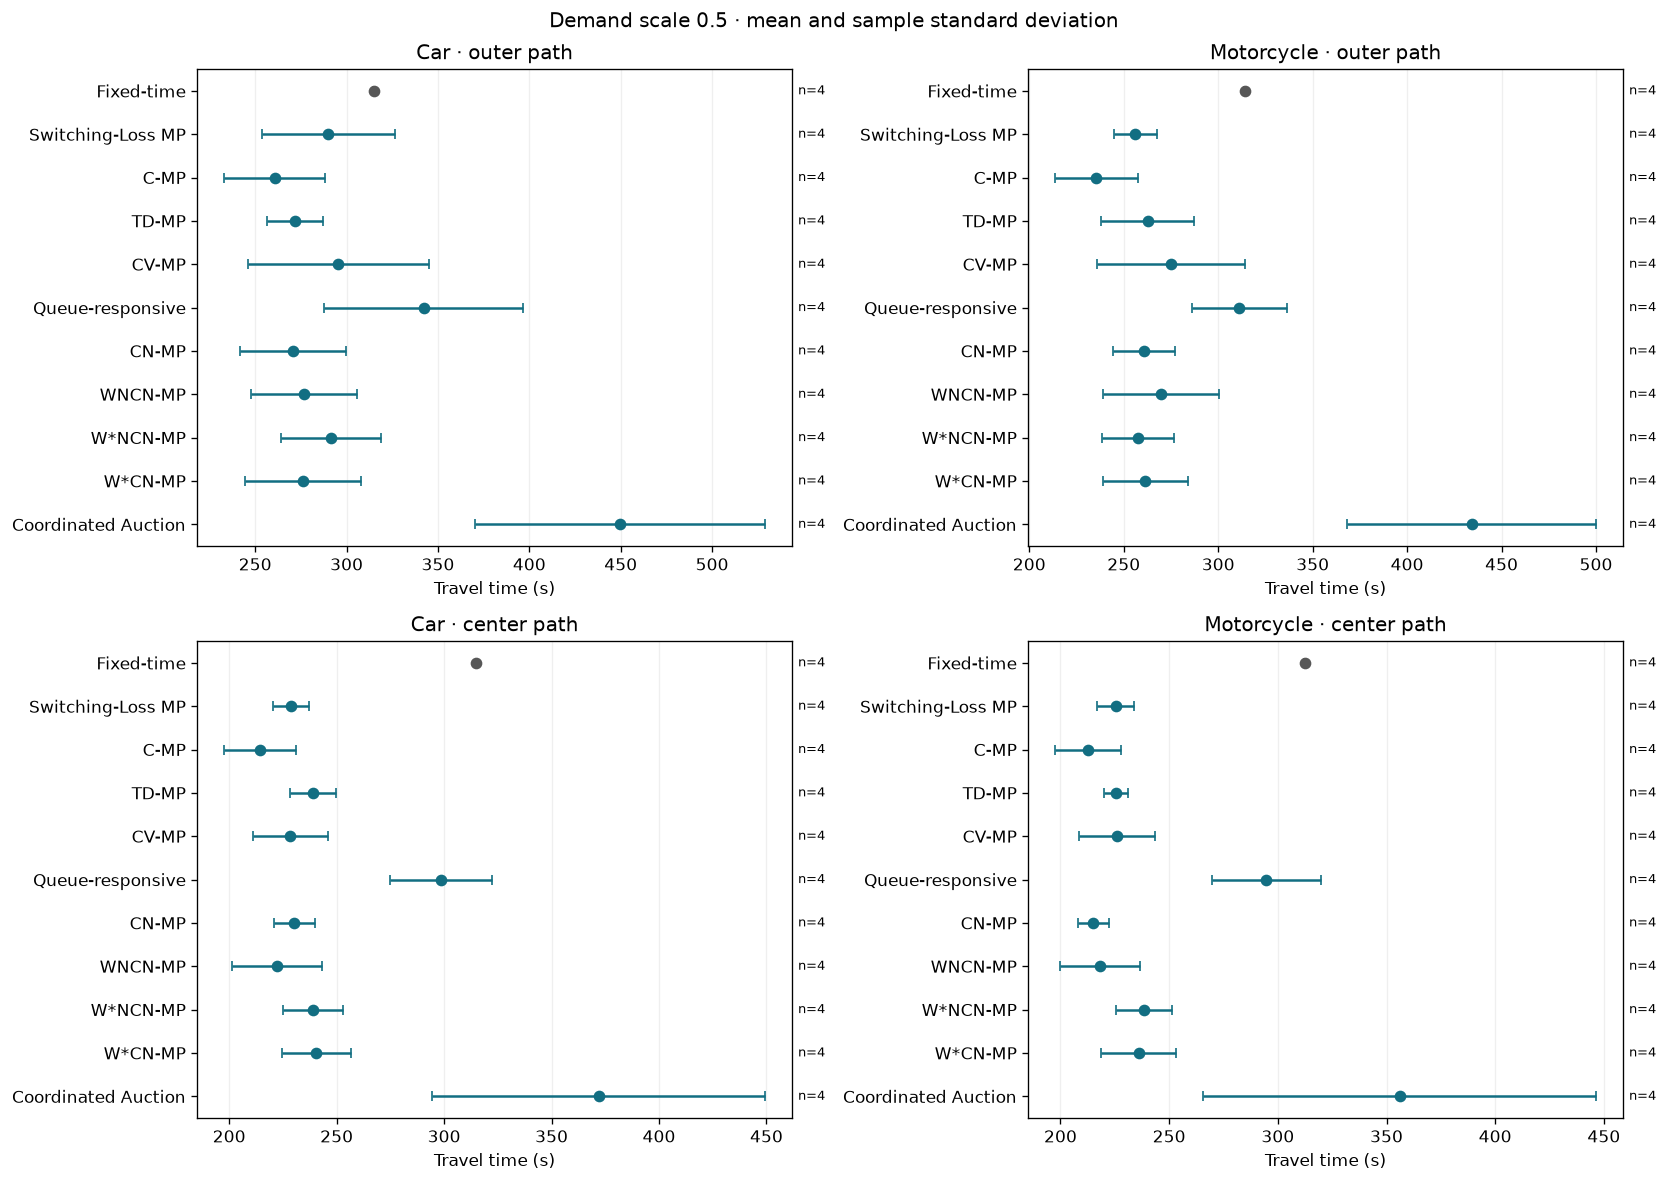

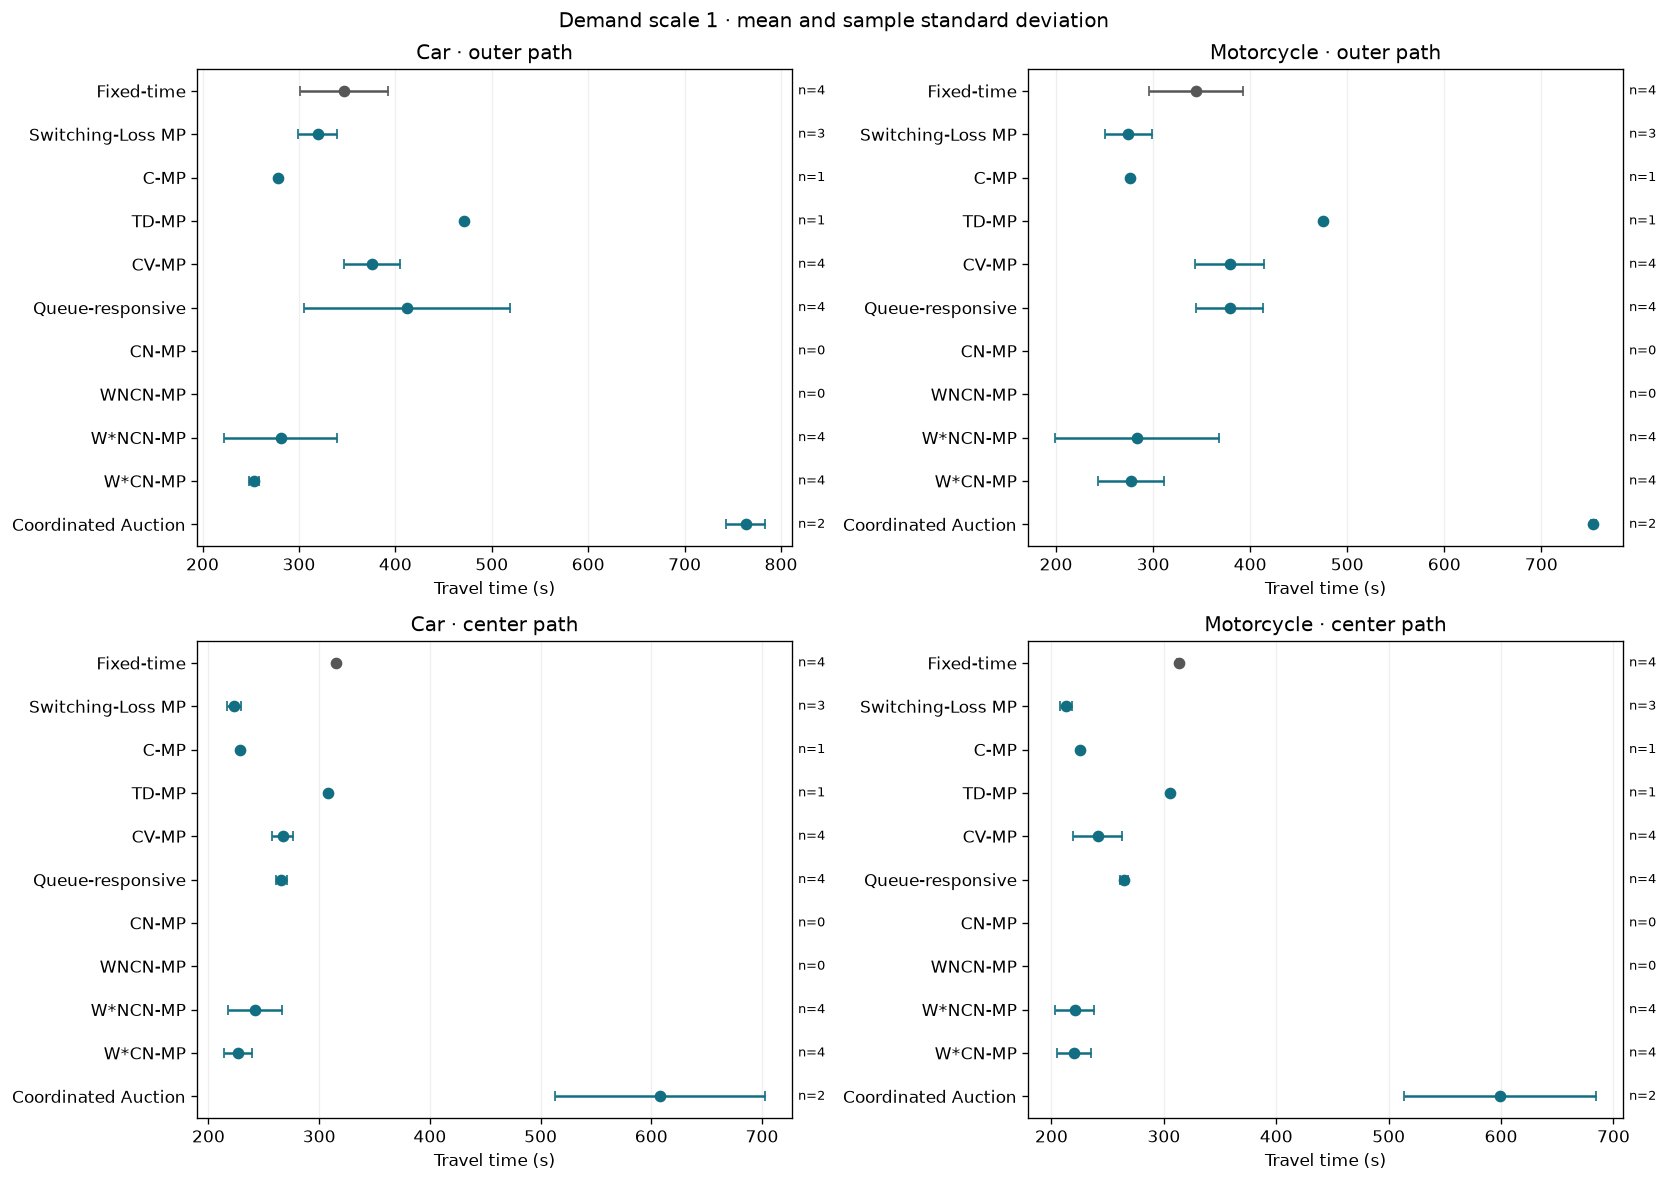

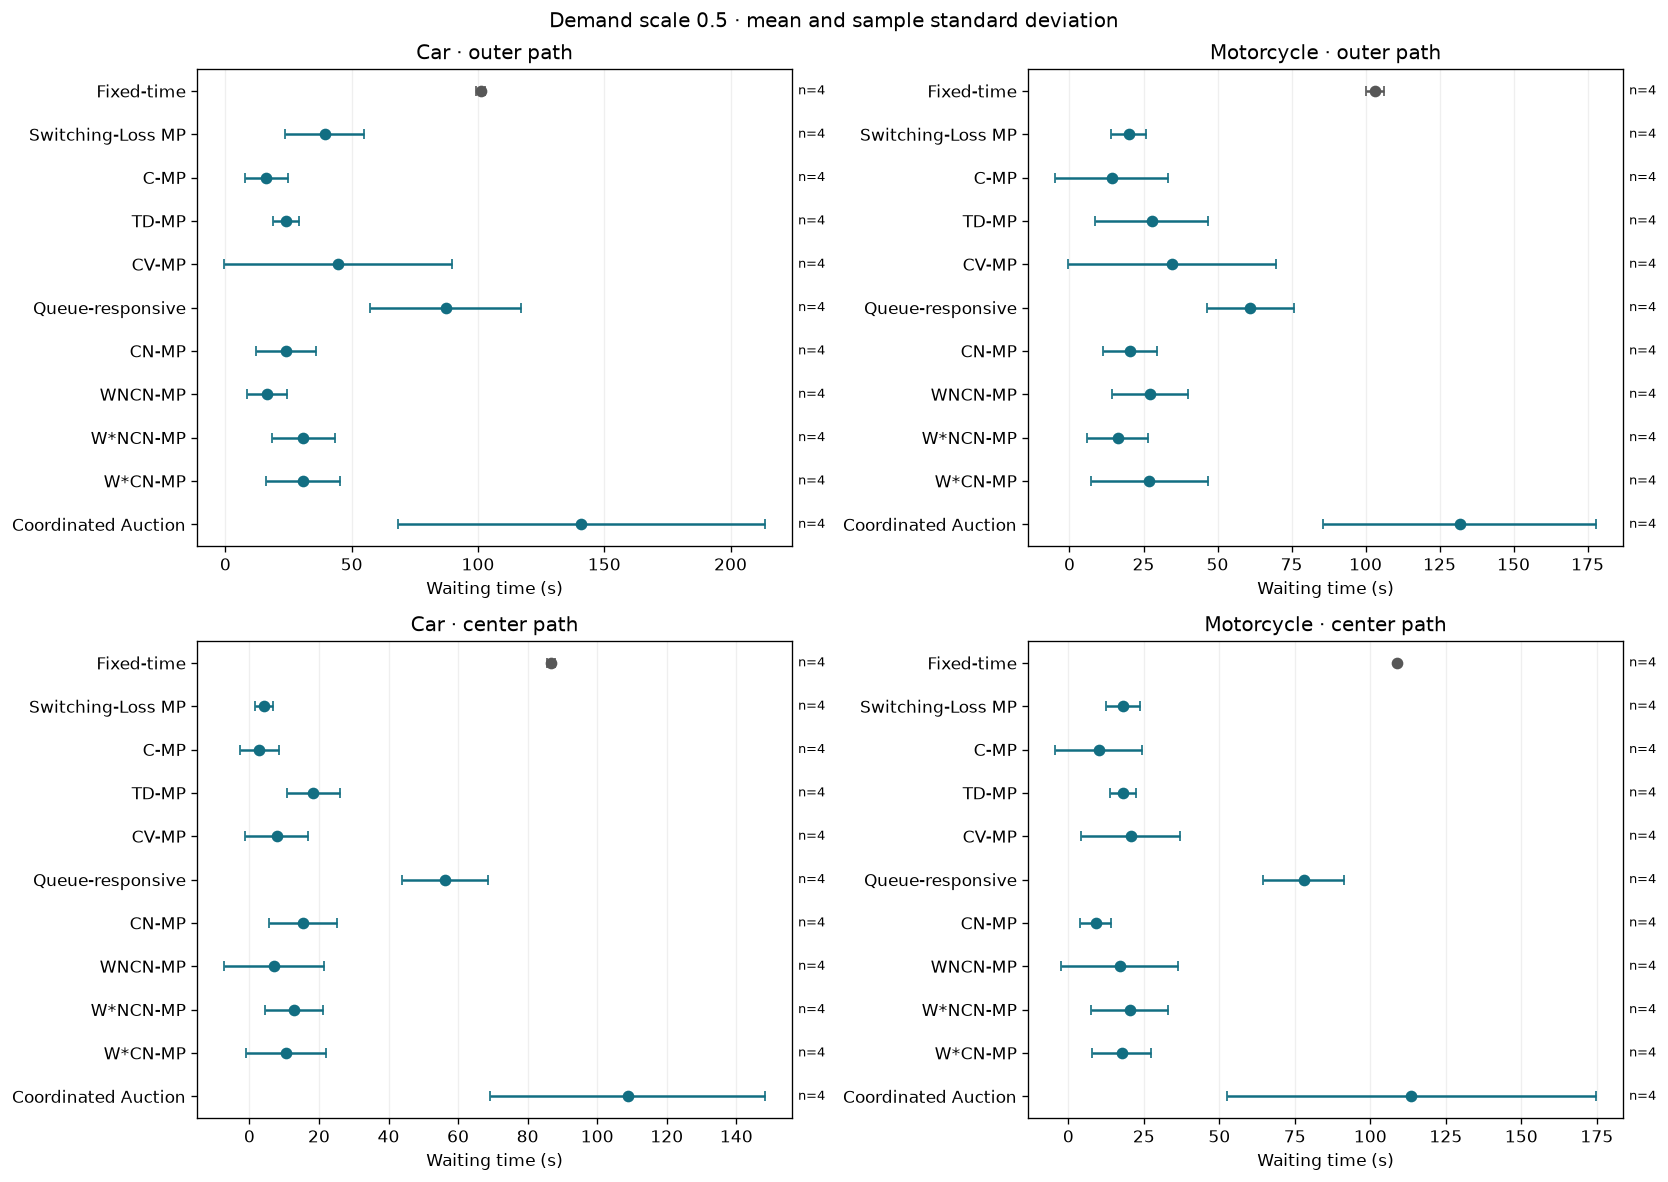

In [8]:
STRATA = [("car", "outer"), ("motorcycle", "outer"), ("car", "center"), ("motorcycle", "center")]

def plot_journeys(scale, metric, deviation, label, filename):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    for ax, (vehicle, path) in zip(axes.flat, STRATA):
        frame = journey_summary.loc[journey_summary["demand_scale"].eq(scale)
            & journey_summary["vehicle_type"].eq(vehicle)
            & journey_summary["route_variant"].eq(path)].set_index("method").reindex(plan["methods"])
        for position, method in enumerate(plan["methods"]):
            row = frame.loc[method]
            if row["valid_seeds"] > 0:
                ax.errorbar(row[metric], position,
                    xerr=0 if pd.isna(row[deviation]) else row[deviation], fmt="o", capsize=3,
                    color="#575757" if method == "fixed_time" else "#126e82")
            ax.text(1.01, position, f"n={int(row['valid_seeds'])}",
                    transform=ax.get_yaxis_transform(), va="center", fontsize=8)
        ax.set_yticks(range(len(frame)), [METHOD_LABELS[m] for m in frame.index])
        ax.invert_yaxis()
        ax.set(title=f"{vehicle.title()} · {path} path", xlabel=label)
        ax.grid(axis="x", alpha=0.2)
    fig.suptitle(f"Demand scale {scale:g} · mean and sample standard deviation")
    fig.tight_layout()
    fig.savefig(OUTPUT / "figures" / filename, dpi=200)
    plt.show()

for scale in sorted(plan["scales"]):
    plot_journeys(scale, "mean_travel_time_s", "std_travel_time_s", "Travel time (s)",
                  f"travel_time_scale_{scale:g}.png")
plot_journeys(FOCUS_SCALE, "mean_waiting_time_s", "std_waiting_time_s", "Waiting time (s)",
              f"waiting_time_scale_{FOCUS_SCALE:g}.png")

## 6. Seed-level distributions

Dots show individual seed results for each vehicle/path group. Boxes describe the observed distribution across the eligible seeds. With four seeds, these plots support descriptive comparisons. They provide limited evidence about population variability.

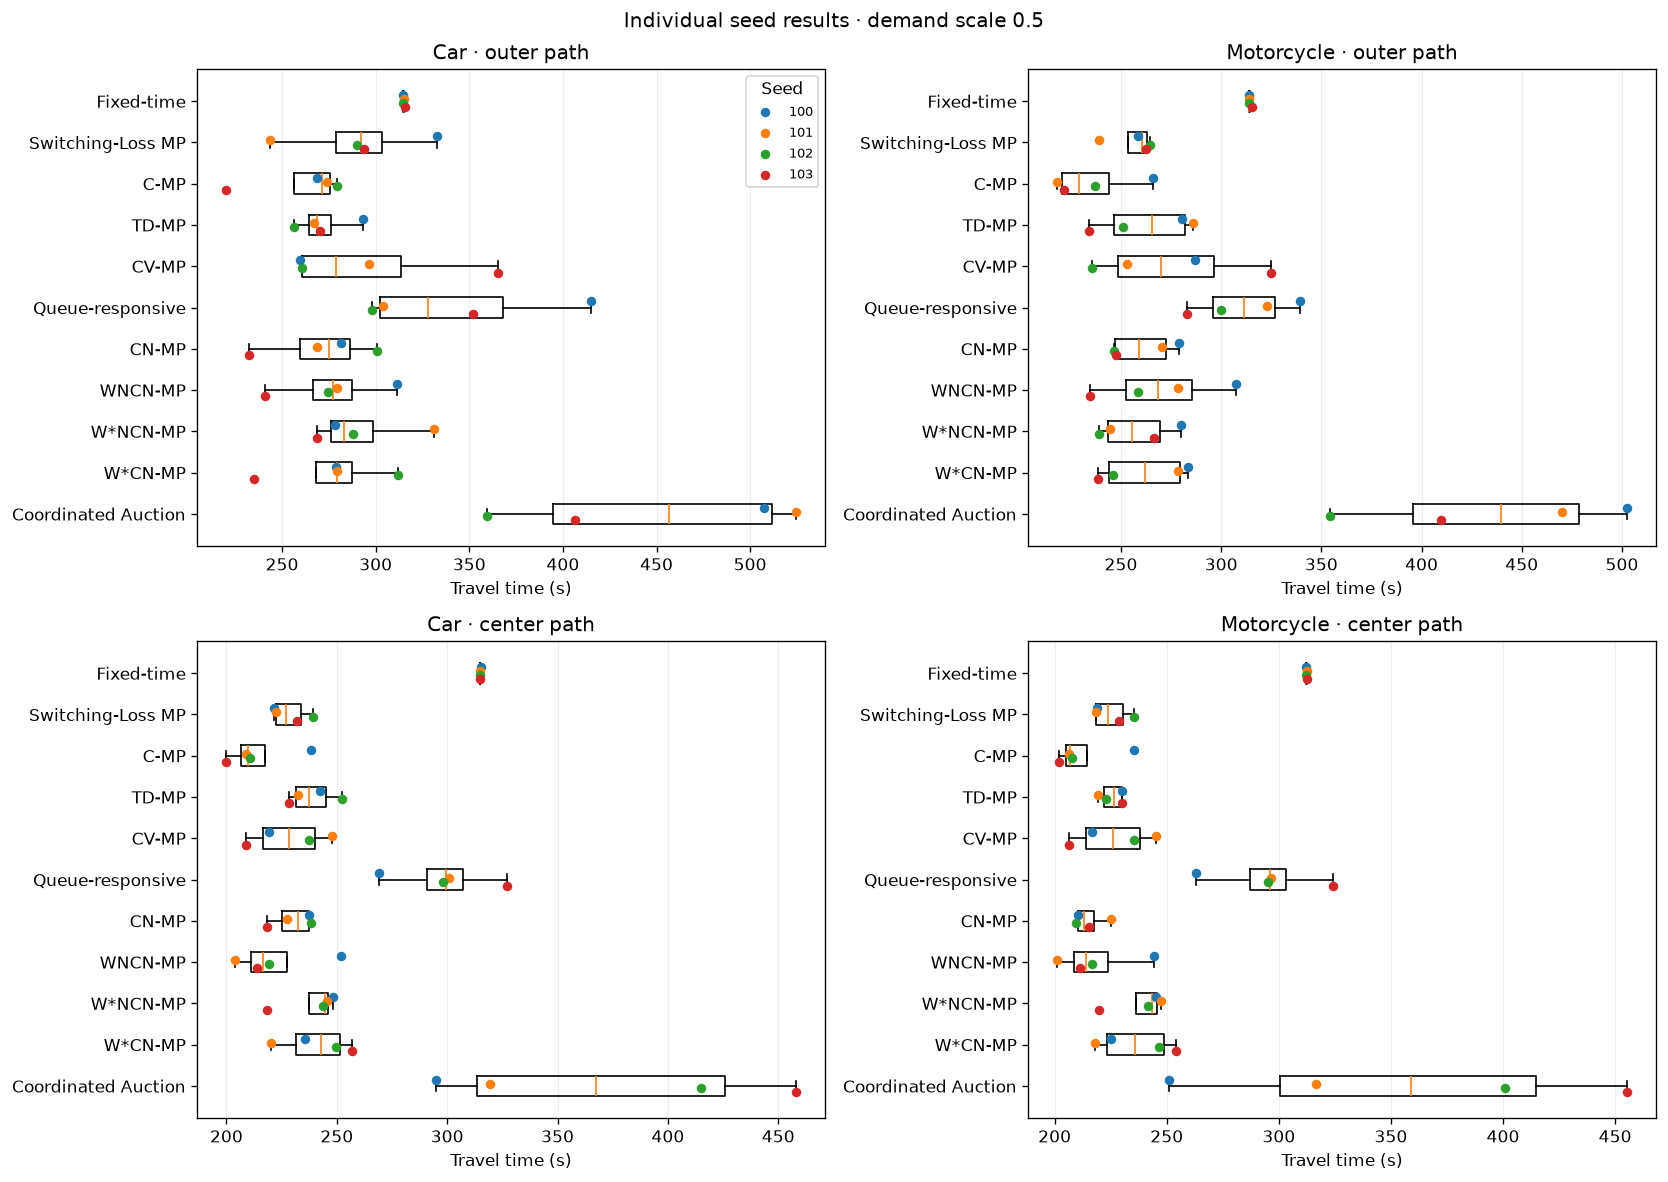

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
colors = plt.cm.tab10(np.arange(len(plan["seeds"])))
for ax, (vehicle, path) in zip(axes.flat, STRATA):
    frame = eligible.loc[eligible["demand_scale"].eq(FOCUS_SCALE)
        & eligible["vehicle_type"].eq(vehicle) & eligible["route_variant"].eq(path)]
    for position, method in enumerate(plan["methods"]):
        sample = frame.loc[frame["method"].eq(method)].sort_values("seed")
        if len(sample):
            ax.boxplot([sample["travel_time_s"].to_numpy()], positions=[position],
                orientation="horizontal", widths=0.5, showfliers=False, manage_ticks=False)
        for index, seed in enumerate(plan["seeds"]):
            point = sample.loc[sample["seed"].eq(seed), "travel_time_s"]
            ax.scatter(point, np.full(len(point), position + (index - 1.5) * 0.1),
                color=colors[index], s=22, zorder=3, label=str(seed) if position == 0 else None)
    ax.set_yticks(range(len(plan["methods"])), [METHOD_LABELS[m] for m in plan["methods"]])
    ax.invert_yaxis()
    ax.set(xlabel="Travel time (s)", title=f"{vehicle.title()} · {path} path")
    ax.grid(axis="x", alpha=0.2)
axes[0, 0].legend(title="Seed", fontsize=8)
fig.suptitle(f"Individual seed results · demand scale {FOCUS_SCALE:g}")
fig.tight_layout()
fig.savefig(OUTPUT / "figures/seed_distributions.png", dpi=200)
plt.show()

## 7. Comparisons between every method

The following table includes both directions of each method pair. Reverse-direction percentages are recalculated using the new reference denominator. Pairwise means can use different eligible seed subsets, so the number of matched seeds is displayed in every heatmap cell.

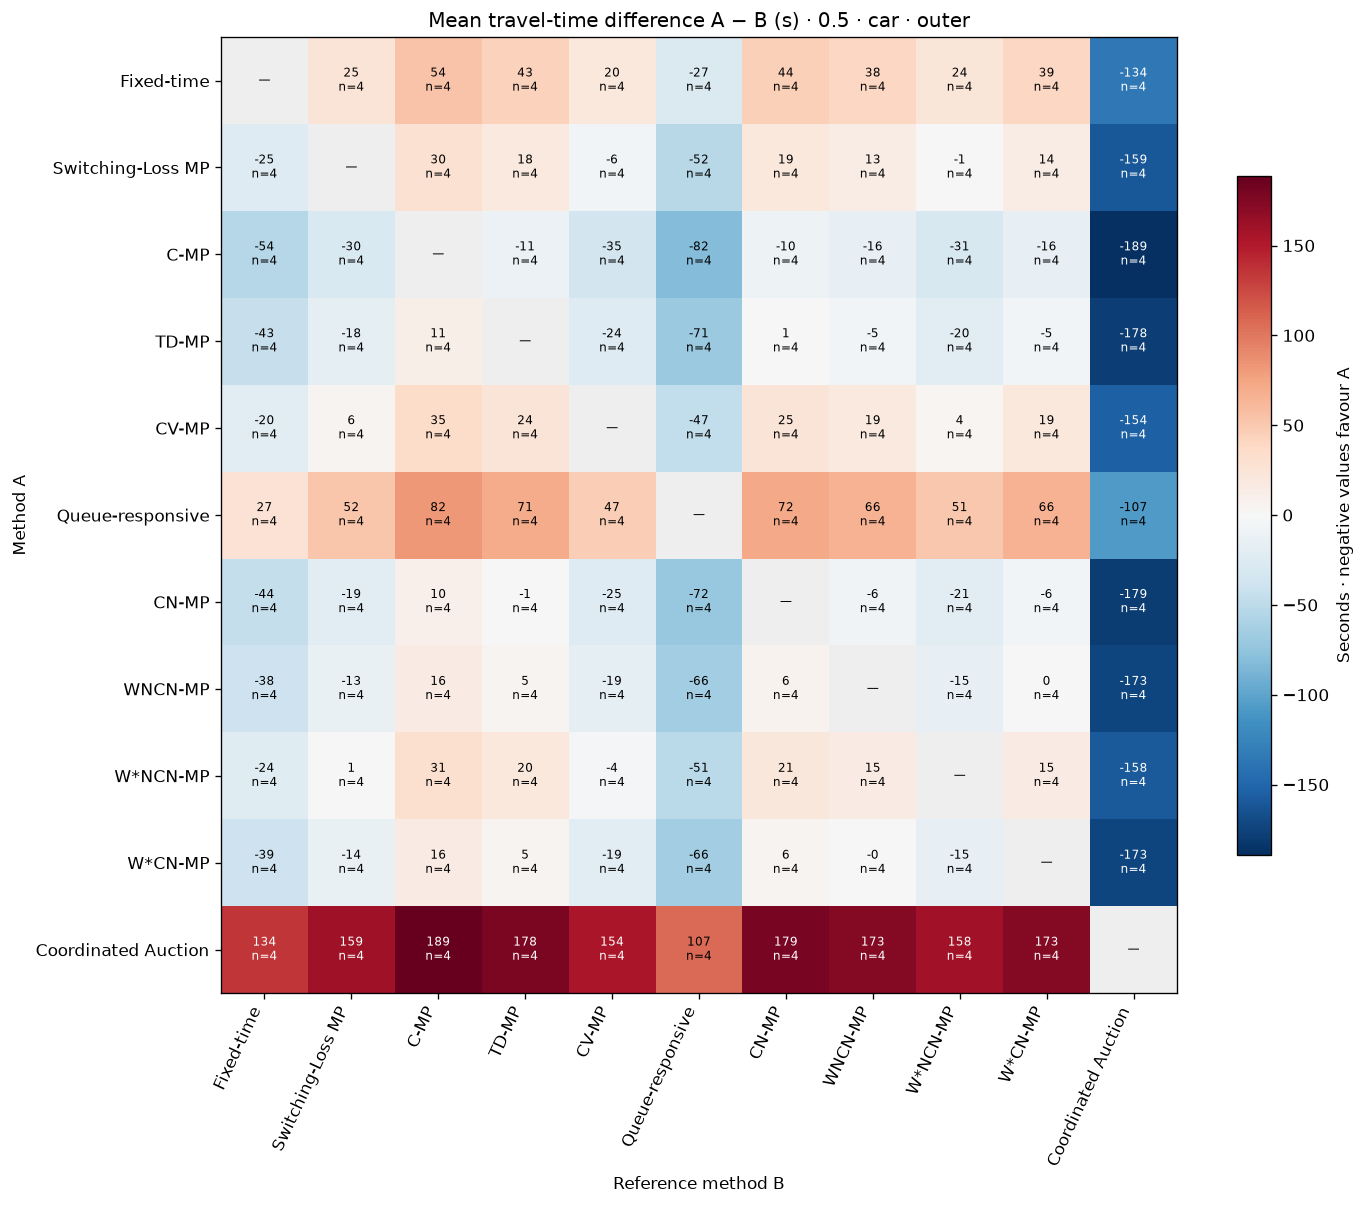

,seed,method_a,method_b,paired_valid,travel_time_a_s,travel_time_b_s,difference_a_minus_b_s,improvement_a_vs_b_percent
3555,100,switching_loss_mp,fixed_time,True,332.50,314.75,17.75,-5.64
3775,101,switching_loss_mp,fixed_time,True,243.50,315.25,-71.75,22.76
3995,102,switching_loss_mp,fixed_time,True,290.25,314.75,-24.50,7.78
4215,103,switching_loss_mp,fixed_time,True,294.00,315.50,-21.50,6.81


In [10]:
reverse = pairs.rename(columns={"method_a": "method_b", "method_b": "method_a",
    "travel_time_a_s": "travel_time_b_s", "travel_time_b_s": "travel_time_a_s",
    "collisions_a": "collisions_b", "collisions_b": "collisions_a",
    "teleports_a": "teleports_b", "teleports_b": "teleports_a",
    "probe_teleported_a": "probe_teleported_b", "probe_teleported_b": "probe_teleported_a"}).copy()
directed_pairs = pd.concat([pairs, reverse], ignore_index=True)
valid = directed_pairs["paired_valid"]
directed_pairs["difference_a_minus_b_s"] = (
    directed_pairs["travel_time_a_s"] - directed_pairs["travel_time_b_s"]).where(valid)
directed_pairs["improvement_a_vs_b_percent"] = (100 *
    (directed_pairs["travel_time_b_s"] - directed_pairs["travel_time_a_s"])
    / directed_pairs["travel_time_b_s"]).where(valid)
PAIR_GROUPS = ["demand_scale", "vehicle_type", "route_variant", "method_a", "method_b"]
pair_summary = directed_pairs.groupby(PAIR_GROUPS).agg(
    paired_seeds=("paired_valid", "sum"), mean_difference_a_minus_b_s=("difference_a_minus_b_s", "mean"),
    std_difference_s=("difference_a_minus_b_s", "std"),
    mean_improvement_a_vs_b_percent=("improvement_a_vs_b_percent", "mean")).reset_index()
focus_pairs = pair_summary.loc[pair_summary["demand_scale"].eq(FOCUS_SCALE)
    & pair_summary["vehicle_type"].eq(FOCUS_VEHICLE)
    & pair_summary["route_variant"].eq(FOCUS_PATH)]
matrix = focus_pairs.pivot(index="method_a", columns="method_b",
    values="mean_difference_a_minus_b_s").reindex(index=plan["methods"], columns=plan["methods"])
pair_counts = focus_pairs.pivot(index="method_a", columns="method_b",
    values="paired_seeds").reindex(index=plan["methods"], columns=plan["methods"])
limit = np.nanmax(np.abs(matrix.to_numpy()))
limit = max(limit, 1)
fig, ax = plt.subplots(figsize=(12, 10))
cmap = plt.cm.RdBu_r.copy()
cmap.set_bad("#eeeeee")
image = ax.imshow(matrix, cmap=cmap, vmin=-limit, vmax=limit)
labels = [METHOD_LABELS[m] for m in plan["methods"]]
ax.set_xticks(range(len(labels)), labels, rotation=65, ha="right")
ax.set_yticks(range(len(labels)), labels)
for row in range(len(labels)):
    for col in range(len(labels)):
        value = matrix.iloc[row, col]
        text = "—" if row == col else ("n=0" if pd.isna(value)
            else f"{value:.0f}\nn={int(pair_counts.iloc[row, col])}")
        ax.text(col, row, text, ha="center", va="center", fontsize=7,
            color="white" if pd.notna(value) and abs(value) > 0.65 * limit else "black")
ax.set(xlabel="Reference method B", ylabel="Method A",
    title=f"Mean travel-time difference A − B (s) · {FOCUS_SCALE:g} · {FOCUS_VEHICLE} · {FOCUS_PATH}")
fig.colorbar(image, ax=ax, label="Seconds · negative values favour A", shrink=0.7)
fig.tight_layout()
fig.savefig(OUTPUT / "figures/all_method_comparison.png", dpi=220)
plt.show()
selected_pair = directed_pairs.loc[directed_pairs["demand_scale"].eq(FOCUS_SCALE)
    & directed_pairs["vehicle_type"].eq(FOCUS_VEHICLE)
    & directed_pairs["route_variant"].eq(FOCUS_PATH)
    & directed_pairs["method_a"].eq(METHOD_A) & directed_pairs["method_b"].eq(METHOD_B)]
display(selected_pair[["seed", "method_a", "method_b", "paired_valid",
    "travel_time_a_s", "travel_time_b_s", "difference_a_minus_b_s", "improvement_a_vs_b_percent"]].round(2))

## 8. Sensitivity to simulation events

The main completion policy retains runs with network events. Two additional policies show how the available evidence changes when affected probes or whole runs are excluded. For each policy, a method-to-fixed-time pair requires both observations to satisfy that policy. The original flags remain in the source dataset.

In [11]:
policies = {
    "All four arrived": data["all_four_arrived"],
    "Exclude affected probes": data["all_four_arrived"] & ~data["probe_collision"] & ~data["probe_teleported"],
    "Zero network events": data["all_four_arrived"] & data["collisions"].eq(0) & data["teleports"].eq(0),
}
sensitivity_counts, sensitivity_tables = [], []
for name, mask in policies.items():
    changed = data.copy()
    changed["valid_for_comparison"] = mask
    rows = changed.astype(object).where(pd.notna(changed), None).to_dict("records")
    refs = {(r["demand_scale"], r["seed"], r["probe_id"]): r
            for r in rows if r["method"] == "fixed_time"}
    flags, policy_gains = [], []
    for row in rows:
        ref = refs[(row["demand_scale"], row["seed"], row["probe_id"])]
        paired = valid_pair(row, ref)
        flags.append(paired)
        policy_gains.append(100 * (ref["travel_time_s"] - row["travel_time_s"])
                            / ref["travel_time_s"] if paired else np.nan)
    changed["policy_gain_percent"] = policy_gains
    sensitivity_counts.append({"policy": name, "eligible_probes": int(mask.sum()),
        "runs_with_eligible_probes": changed.loc[mask, "run_id"].nunique(),
        "paired_probe_rows_including_fixed": sum(flags)})
    table = changed.loc[mask].groupby(GROUPS).agg(
        eligible_seeds=("seed", "size"), mean_travel_time_s=("travel_time_s", "mean"),
        paired_seeds=("policy_gain_percent", "count"), mean_gain_percent=("policy_gain_percent", "mean"))
    table = counts.join(table).reset_index()
    table["policy"] = name
    sensitivity_tables.append(table)
sensitivity_coverage = pd.DataFrame(sensitivity_counts)
sensitivity_summary = pd.concat(sensitivity_tables, ignore_index=True)
display(sensitivity_coverage)

,policy,eligible_probes,runs_with_eligible_probes,paired_probe_rows_including_fixed
0,All four arrived,460,115,460
1,Exclude affected probes,459,115,459
2,Zero network events,148,37,108


## 9. Missing values, exposure and interpretation

Missing arrival-based measures are expected for censored journeys. Conditional travel-time means should be read alongside completion coverage. A controller with fewer completed seeds can have a faster conditional mean while completing fewer journeys.

Simulation runs stop after tracked journeys finish or at the time limit. Their durations differ. Raw network arrivals and event totals therefore have different exposure periods and cannot establish a ranking of throughput or safety rates.

The source audit remains `accepted = false`. Results describe the implemented model and the recorded simulation events. Four seeds per demand level support descriptive comparisons with explicit sample counts. Vehicle types and paths remain separate throughout the analysis.

In [12]:
missing = data.isna().sum().rename("missing_rows").to_frame()
missing["missing_percent"] = 100 * missing["missing_rows"] / len(data)
display(missing.loc[missing["missing_rows"].gt(0)].round(2))
run_windows = runs.groupby(["demand_scale", "method"]).agg(
    runs=("run_id", "size"), mean_end_s=("actual_end_s", "mean"),
    minimum_end_s=("actual_end_s", "min"), maximum_end_s=("actual_end_s", "max"),
    collisions=("collisions", "sum"), teleports=("teleports", "sum")).reset_index()
display(run_windows.round(2))

,missing_rows,missing_percent
travel_time_s,34,6.44
route_length_m,34,6.44
mean_speed_kmh,34,6.44
time_loss_s,34,6.44
waiting_count,34,6.44
arrival_s,34,6.44
phase_switches,48,9.09
improvement_vs_fixed_percent,68,12.88


,demand_scale,method,runs,mean_end_s,minimum_end_s,maximum_end_s,collisions,teleports
0,0.1,c_mp,4,526.56,511.75,537.75,1,1
1,0.1,cn_mp_2024,4,511.06,506.25,519.50,1,1
2,0.1,coordinated_auction_2024,4,577.56,521.50,648.00,1,1
3,0.1,cv_mp_2025,4,539.88,529.00,559.25,0,0
4,0.1,fixed_time,4,615.94,615.75,616.25,1,1
5,0.1,queue_responsive_2026,4,576.44,558.50,608.00,0,0
6,0.1,switching_loss_mp,4,523.06,517.00,535.50,0,0
7,0.1,td_mp_2023,4,531.75,528.00,534.75,2,2
8,0.1,wncn_mp_2024,4,517.38,510.25,522.00,2,2
9,0.1,wstar_cn_mp_2024,4,528.31,508.00,558.00,1,1


## 10. Export the calculated evidence

CSV tables and PNG figures are written under `analysis/outputs/cong_hoa_132_runs`. The manifest records source hashes, package versions and the selected plot settings. Bibliographic sources remain in the project documentation.

In [13]:
exports = {
    "coverage": coverage.reset_index(), "completion_by_method": completion.reset_index(),
    "probe_events": probe_events, "baseline_summary": baseline,
    "journey_summary": journey_summary, "fixed_time_pairs": fixed_pairs,
    "method_pairs": pairs, "method_pair_summary": pair_summary,
    "sensitivity_coverage": sensitivity_coverage, "sensitivity_summary": sensitivity_summary,
    "missing_values": missing.reset_index(names="column"), "run_windows": run_windows,
}
for name, frame in exports.items():
    frame.to_csv(OUTPUT / f"{name}.csv", index=False)
assert source_hashes == {name: sha256(SOURCE / name) for name in source_hashes}
manifest = {
    "source_checkpoint": str(SOURCE.relative_to(ROOT)), "source_sha256": source_hashes,
    "source_accepted": snapshot["accepted"], "comparison_policy": "all_four_arrived",
    "run_count": len(runs), "probe_count": len(data), "seed_count": len(plan["seeds"]),
    "focus": {"scale": FOCUS_SCALE, "vehicle": FOCUS_VEHICLE, "path": FOCUS_PATH},
    "packages": {name: metadata.version(name) for name in
                 ["pandas", "numpy", "matplotlib", "nbformat", "nbclient", "ipykernel", "libsumo"]},
}
(OUTPUT / "analysis_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("All consistency checks passed.")
print("Exported", len(exports), "tables to", OUTPUT)
print("Source audit accepted", manifest["source_accepted"])

All consistency checks passed.
Exported 12 tables to D:\UoG\Year 3\Final Year Project\NetWorks\grid20\analysis\outputs\cong_hoa_132_runs
Source audit accepted False


## 11. Publication figures and complete method coverage

These exports contain all ten research controllers and the fixed-time reference. Each journey figure contains one vehicle type, one path and one demand scale. All-method pairwise figures are exported for each of these twelve strata. Method identifiers on heatmap columns match the identifiers beside the row names.

Travel and waiting figures show mean ± sample standard deviation. The displayed n is the eligible seed count. A single observation has no estimated standard deviation. Blank estimates retain n = 0. Pairwise cells show mean A − B and matched n, with a blue cell favouring the row method. Different pairs may use different seed subsets.

Use single-panel journey figures at approximately 16 cm width. Pairwise figures suit a landscape page at approximately 23 cm width. Full comparison tables are exported for every demand level. The same source completion policy applies throughout.


In [14]:
PAPER = OUTPUT / "paper"
(PAPER / "figures").mkdir(parents=True, exist_ok=True)
(PAPER / "tables").mkdir(exist_ok=True)
method_ids = {method: f"M{index}" for index, method in enumerate(plan["methods"])}
method_key = pd.DataFrame({"method_id": [method_ids[m] for m in plan["methods"]],
    "method": plan["methods"], "label": [METHOD_LABELS[m] for m in plan["methods"]]})
method_key.to_csv(PAPER / "tables/method_key.csv", index=False)

for scale in sorted(plan["scales"]):
    scale_summary = journey_summary.loc[journey_summary["demand_scale"].eq(scale)].copy()
    scale_summary["group"] = scale_summary["vehicle_type"] + "_" + scale_summary["route_variant"]
    for metric in ["mean_travel_time_s", "mean_waiting_time_s", "mean_improvement_vs_fixed_percent", "valid_seeds"]:
        full_table = scale_summary.pivot(index="method", columns="group", values=metric).reindex(plan["methods"])
        assert len(full_table) == 11
        full_table.rename(index=METHOD_LABELS).to_csv(PAPER / f"tables/{metric}_scale_{scale:g}.csv")
    for vehicle, path_name in STRATA:
        frame = scale_summary.loc[scale_summary["vehicle_type"].eq(vehicle)
            & scale_summary["route_variant"].eq(path_name)].set_index("method").reindex(plan["methods"])
        suffix = f"scale_{scale:g}_{vehicle}_{path_name}"
        for metric, deviation, label, prefix in [
            ("mean_travel_time_s", "std_travel_time_s", "Travel time (s)", "travel"),
            ("mean_waiting_time_s", "std_waiting_time_s", "Waiting time (s)", "waiting")]:
            fig, ax = plt.subplots(figsize=(7.1, 5.2))
            for position, method in enumerate(plan["methods"]):
                row = frame.loc[method]
                if row["valid_seeds"] > 0:
                    error = 0 if pd.isna(row[deviation]) else row[deviation]
                    ax.errorbar(row[metric], position, xerr=error, fmt="o", capsize=3,
                        color="#525252" if method == "fixed_time" else "#13768a")
                ax.text(1.02, position, f"n={int(row['valid_seeds'])}", va="center",
                    transform=ax.get_yaxis_transform(), fontsize=9)
            ax.set_yticks(range(11), [METHOD_LABELS[m] for m in plan["methods"]], fontsize=10)
            ax.invert_yaxis()
            ax.set_xlabel(label, fontsize=11)
            ax.set_title(f"{vehicle.title()} / {path_name} path / demand scale {scale:g}", fontsize=12, pad=12)
            ax.grid(axis="x", alpha=0.2)
            fig.subplots_adjust(left=0.32, right=0.88, bottom=0.13, top=0.90)
            for extension in ["png", "pdf"]:
                fig.savefig(PAPER / f"figures/{prefix}_{suffix}.{extension}", dpi=300)
            plt.close(fig)
        chosen = pair_summary.loc[pair_summary["demand_scale"].eq(scale)
            & pair_summary["vehicle_type"].eq(vehicle)
            & pair_summary["route_variant"].eq(path_name)]
        matrix = chosen.pivot(index="method_a", columns="method_b", values="mean_difference_a_minus_b_s").reindex(
            index=plan["methods"], columns=plan["methods"])
        pair_n = chosen.pivot(index="method_a", columns="method_b", values="paired_seeds").reindex(
            index=plan["methods"], columns=plan["methods"])
        limit = max(float(np.nanmax(np.abs(matrix.to_numpy()))), 1)
        cmap = plt.cm.RdBu_r.copy()
        cmap.set_bad("#eeeeee")
        fig, ax = plt.subplots(figsize=(9.4, 7.3))
        heat = ax.imshow(matrix, vmin=-limit, vmax=limit, cmap=cmap, aspect="equal")
        ax.set_xticks(range(11), [method_ids[m] for m in plan["methods"]], fontsize=10)
        ax.set_yticks(range(11), [f"{method_ids[m]}  {METHOD_LABELS[m]}" for m in plan["methods"]], fontsize=10)
        for row in range(11):
            for column in range(11):
                value = matrix.iloc[row, column]
                text = "—" if row == column else ("n=0" if pd.isna(value)
                    else f"{value:.0f}\nn={int(pair_n.iloc[row, column])}")
                ax.text(column, row, text, ha="center", va="center", fontsize=8.5,
                    color="white" if pd.notna(value) and abs(value) > 0.65 * limit else "black")
        ax.set_xlabel("Reference method B", fontsize=11, labelpad=10)
        ax.set_ylabel("Method A", fontsize=11)
        ax.set_title(f"{vehicle.title()} / {path_name} path / demand scale {scale:g}", fontsize=12, pad=13)
        fig.subplots_adjust(left=0.28, right=0.91, bottom=0.11, top=0.91)
        cax = fig.add_axes([0.93, 0.24, 0.016, 0.50])
        fig.colorbar(heat, cax=cax, label="Mean A − B (s)")
        for extension in ["png", "pdf"]:
            fig.savefig(PAPER / f"figures/pairwise_{suffix}.{extension}", dpi=300)
        plt.close(fig)
        chosen.to_csv(PAPER / f"tables/pairwise_{suffix}.csv", index=False)

print("Publication exports", PAPER)
print("Complete comparison tables", len(list((PAPER / "tables").glob("*.csv"))))
print("Single-panel PNG figures", len(list((PAPER / "figures").glob("*.png"))))
print("Vector PDF figures", len(list((PAPER / "figures").glob("*.pdf"))))


Publication exports D:\UoG\Year 3\Final Year Project\NetWorks\grid20\analysis\outputs\cong_hoa_132_runs\paper
Complete comparison tables 25
Single-panel PNG figures 36
Vector PDF figures 36


## 12. Complete pairwise Results appendix

The appendix below retains all 55 unique method pairs at each demand scale. Each table separates the four vehicle–path groups. Missing comparisons display n = 0. At scale 1.0, the matching seed subset can differ between pairs, so the pairwise difference is calculated directly from common eligible seeds.


In [15]:
from itertools import combinations

appendix_path = PAPER / "COMPLETE_PAIRWISE_RESULTS.md"
stratum_order = [("car", "outer"), ("motorcycle", "outer"), ("car", "center"), ("motorcycle", "center")]
lookup = pair_summary.set_index(["demand_scale", "vehicle_type", "route_variant", "method_a", "method_b"])
lines = [
    "# Complete comparisons between all signal-control methods", "",
    "## Replacement Results subsection", "",
    "All ten research controllers and the fixed-time reference were included in the pairwise analysis. Eleven methods produced 55 unique method pairs within each demand, vehicle-type and path group. Each comparison matched the same seed, tracked journey and simulation inputs. Mean differences were calculated from the common eligible seeds for the two methods.", "",
    "At demand scales 0.1 and 0.5, all 55 pairs were available in every vehicle–path group, with four matched seeds per pair. At scale 1.0, 36 pairs were available in each group. Ten of these pairs retained four matched seeds. The remaining available pairs used smaller matched subsets. Nineteen pairs were unavailable because they involved CN-MP or WNCN-MP, which had no runs satisfying the all-four-arrived criterion.", "",
    "At scale 0.1, Switching-Loss MP produced the lowest outer-car mean, while CN-MP produced the lowest means in the other three groups. WNCN-MP and W*NCN-MP also produced relatively short central-path journeys. C-MP, TD-MP, CV-MP and W*CN-MP improved on fixed-time across all groups, with different relative advantages by vehicle and path. Queue-responsive control and Coordinated Auction also reduced mean travel times relative to fixed-time at this demand level, although their improvements were generally smaller than those of the leading pressure-based methods.", "",
    "At scale 0.5, C-MP had a lower paired mean travel time than every other method in all four groups. The relative position of CN-MP, WNCN-MP, W*NCN-MP, W*CN-MP, Switching-Loss MP, TD-MP and CV-MP depended on vehicle type and path. For example, CN-MP was faster than WNCN-MP for outer cars, while WNCN-MP was faster for central cars. Switching-Loss MP was faster than TD-MP for outer motorcycles, while TD-MP was faster for outer cars. Queue-responsive control produced a longer outer-car journey than fixed-time, with shorter means in the other groups. Coordinated Auction produced longer journeys than fixed-time in every group.", "",
    "At scale 1.0, W*CN-MP had the lowest means in all four groups among the five methods retaining four eligible seeds. These five methods were fixed-time, CV-MP, queue-responsive control, W*NCN-MP and W*CN-MP. Switching-Loss MP retained three eligible seeds. On its common seeds with W*CN-MP, Switching-Loss MP was faster by an average of 4.92 seconds for central cars, 10.58 seconds for central motorcycles and 8.50 seconds for outer motorcycles. W*CN-MP was faster by 64.42 seconds for outer cars. These results demonstrate why high-demand pairwise differences must use matched seeds.", "",
    "C-MP and TD-MP each retained one eligible seed at scale 1.0. C-MP recorded relatively short journeys in that seed, while TD-MP recorded longer outer-path journeys than its matched fixed-time observations. CV-MP and queue-responsive control improved central-path travel times relative to fixed-time and produced longer outer-path journeys. W*NCN-MP improved on fixed-time in all four groups. Coordinated Auction retained two eligible seeds and recorded substantially longer journeys. CN-MP and WNCN-MP retained their completion results in the analysis, with no eligible travel-time means under the selected policy.", "",
    "These pairwise results are descriptive. Completion coverage, unequal matched sample sizes and recorded simulation events remain relevant to their interpretation. The source dataset audit records accepted = false.", "",
    "## Complete comparison tables", "",
    "Each cell reports the mean travel-time difference A minus B in seconds, followed by the matched seed count in parentheses. Negative values favour A. Positive values favour B. A dash with n = 0 denotes an unavailable comparison. The tables use the all-four-arrived inclusion policy and retain event-affected runs under that policy.", "",
]
long_rows = []
for scale in sorted(plan["scales"]):
    lines += [f"### Demand scale {scale:g}", "",
        "| Method A | Method B | Outer car | Outer motorcycle | Central car | Central motorcycle |",
        "|---|---|---:|---:|---:|---:|"]
    for first, second in combinations(plan["methods"], 2):
        values = []
        for vehicle, path_name in stratum_order:
            row = lookup.loc[(scale, vehicle, path_name, first, second)]
            count = int(row["paired_seeds"])
            difference = row["mean_difference_a_minus_b_s"]
            values.append("— (n=0)" if count == 0 else f"{difference:.2f} (n={count})")
            long_rows.append({"demand_scale": scale, "vehicle_type": vehicle, "route_variant": path_name,
                "method_a": first, "method_b": second, "paired_seeds": count,
                "mean_difference_a_minus_b_s": difference,
                "std_difference_s": row["std_difference_s"],
                "mean_improvement_a_vs_b_percent": row["mean_improvement_a_vs_b_percent"]})
        lines.append("| " + METHOD_LABELS[first] + " | " + METHOD_LABELS[second] + " | " + " | ".join(values) + " |")
    lines += [""]
complete_pairs = pd.DataFrame(long_rows)
assert len(complete_pairs) == 55 * 3 * 4
assert complete_pairs.groupby(["demand_scale", "vehicle_type", "route_variant"]).size().eq(55).all()
appendix_path.write_text("\n".join(lines), encoding="utf-8")
complete_pairs.to_csv(PAPER / "tables/complete_unique_pairwise_summary.csv", index=False)
display(complete_pairs.groupby(["demand_scale", "vehicle_type", "route_variant"]).agg(
    total_pairs=("paired_seeds", "size"),
    available_pairs=("paired_seeds", lambda counts: counts.gt(0).sum()),
    four_seed_pairs=("paired_seeds", lambda counts: counts.eq(4).sum())))
print("Complete comparison appendix", appendix_path)


total_pairs  available_pairs  \
demand_scale vehicle_type route_variant                                 
0.1          car          center                  55               55   
                          outer                   55               55   
             motorcycle   center                  55               55   
                          outer                   55               55   
0.5          car          center                  55               55   
                          outer                   55               55   
             motorcycle   center                  55               55   
                          outer                   55               55   
1.0          car          center                  55               36   
                          outer                   55               36   
             motorcycle   center                  55               36   
                          outer                   55               36   

                                         four_seed_pairs  
demand_scale vehicle_type route_variant                   
0.1          car          center                      55  
                          outer                       55  
             motorcycle   center                      55  
                          outer                       55  
0.5          car          center                      55  
                          outer                       55  
             motorcycle   center                      55  
                          outer                       55  
1.0          car          center                      10  
                          outer                       10  
             motorcycle   center                      10  
                          outer                       10

Complete comparison appendix D:\UoG\Year 3\Final Year Project\NetWorks\grid20\analysis\outputs\cong_hoa_132_runs\paper\COMPLETE_PAIRWISE_RESULTS.md


## 13. Travel-time overview heatmaps for the Results chapter

Each figure compares every method across the four vehicle–path groups at one demand scale. Cells show mean travel time in seconds. All figures share the same colour limits, allowing demand levels to be compared visually. The high-demand figure also reports eligible seed counts. Grey cells indicate unavailable means under the all-four-arrived policy.


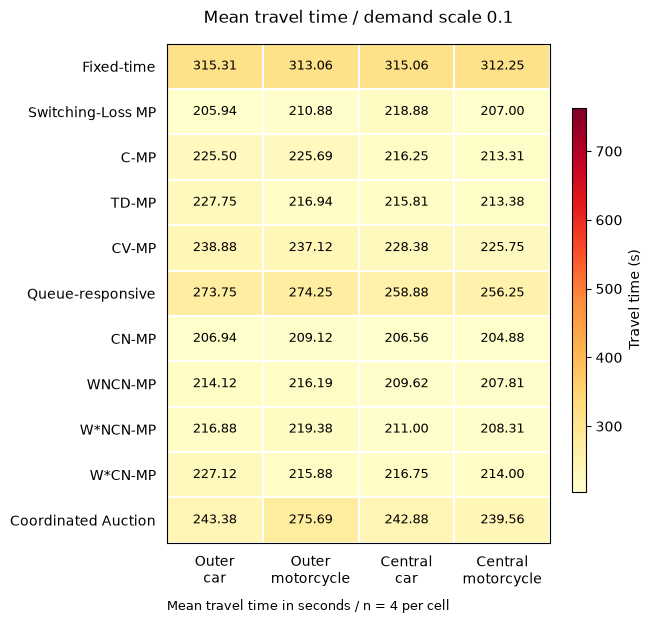

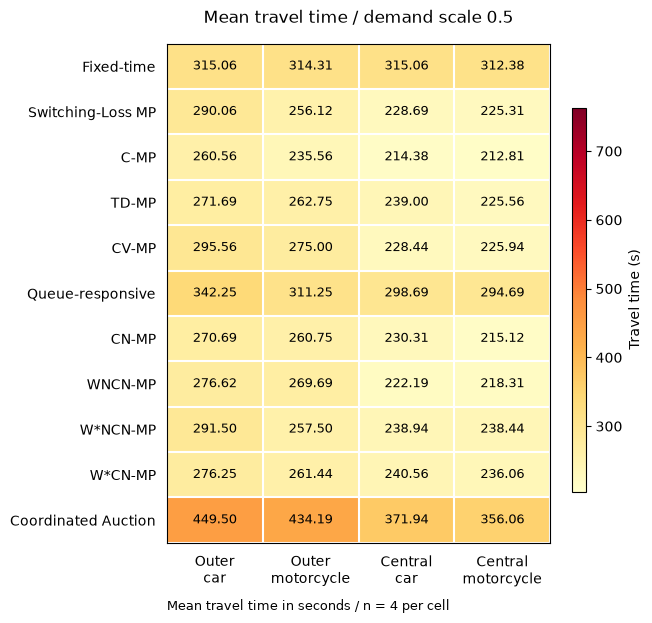

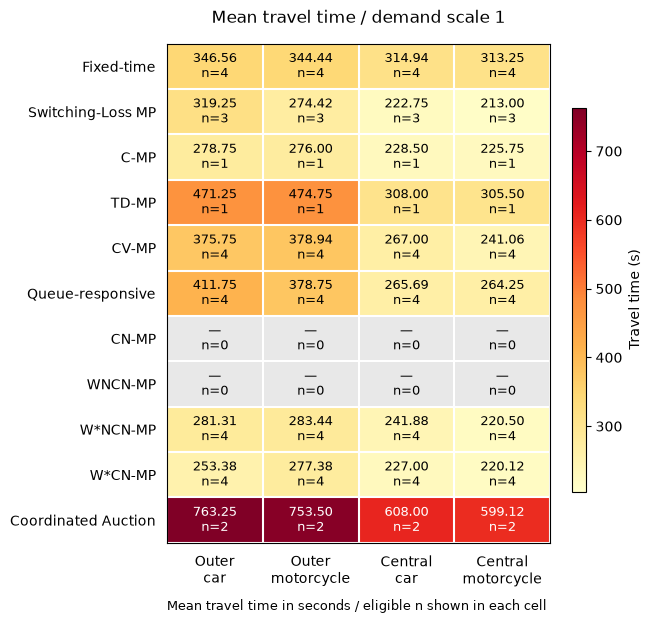

Overview heatmaps include all 11 methods and four journey groups.


In [16]:
overview_groups = [("car", "outer"), ("motorcycle", "outer"), ("car", "center"), ("motorcycle", "center")]
overview_labels = ["Outer\ncar", "Outer\nmotorcycle", "Central\ncar", "Central\nmotorcycle"]
minimum_time = journey_summary["mean_travel_time_s"].min()
maximum_time = journey_summary["mean_travel_time_s"].max()
for scale in sorted(plan["scales"]):
    selected = journey_summary.loc[journey_summary["demand_scale"].eq(scale)]
    values = selected.pivot(index="method", columns=["vehicle_type", "route_variant"],
        values="mean_travel_time_s").reindex(index=plan["methods"], columns=overview_groups)
    sample_sizes = selected.pivot(index="method", columns=["vehicle_type", "route_variant"],
        values="valid_seeds").reindex(index=plan["methods"], columns=overview_groups)
    assert values.shape == (11, 4)
    fig, ax = plt.subplots(figsize=(7.1, 6.4))
    cmap = plt.cm.YlOrRd.copy()
    cmap.set_bad("#e8e8e8")
    heat = ax.imshow(values.to_numpy(), cmap=cmap, vmin=minimum_time,
        vmax=maximum_time, aspect="auto")
    ax.set_yticks(range(11), [METHOD_LABELS[m] for m in plan["methods"]], fontsize=10)
    ax.set_xticks(range(4), overview_labels, fontsize=10)
    ax.tick_params(axis="both", length=0, pad=8)
    ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 11, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)
    for row in range(11):
        for column in range(4):
            value = values.iloc[row, column]
            count = int(sample_sizes.iloc[row, column])
            text = "—\nn=0" if pd.isna(value) else f"{value:.2f}"
            if pd.notna(value) and scale == 1.0:
                text += f"\nn={count}"
            dark = pd.notna(value) and (value-minimum_time)/(maximum_time-minimum_time) > 0.65
            ax.text(column, row, text, ha="center", va="center", fontsize=9,
                color="white" if dark else "black")
    ax.set_title(f"Mean travel time / demand scale {scale:g}", fontsize=12, pad=15)
    note = "Mean travel time in seconds / n = 4 per cell" if scale != 1.0 else "Mean travel time in seconds / eligible n shown in each cell"
    fig.text(0.32, 0.035, note, fontsize=9)
    fig.subplots_adjust(left=0.32, right=0.86, top=0.92, bottom=0.14)
    cax = fig.add_axes([0.89, 0.22, 0.02, 0.60])
    fig.colorbar(heat, cax=cax, label="Travel time (s)")
    fig.savefig(PAPER / f"figures/travel_overview_scale_{scale:g}.png", dpi=300)
    plt.show()
print("Overview heatmaps include all 11 methods and four journey groups.")
